#### Oppsummering av sentrale punkter og refleksjon ELK330

<div style="display:flex;margin-top:50px;">

<div style="width:50%;text-align:center;">

**3D**
    
- Digitalisering
    
- Dekarbonisering
    
- Desentralisering
</div>

<div style="width:30%; text-align:center;">
<img src="../images/digital_tvilling.svg" width="300">


</div>

<div style="width:30%; text-align:center;">
<img src="lastprofilinfo.svg" width="400">


</div>
    
</div>



#### Datadrevne og matematiske modeller

<div style="display:flex;margin-top:5px;">



<div style="width:33%; text-align:center;">
<img src="../04_reprdag/representative_day.svg" width="400">



</div>
    
<div style="width:33%; text-align:center;">
<img src="../images/bias_var_accuracy.svg" width="300">



</div>

<div style="width:33%; text-align:center;">
<img src="gauss_model1.svg" width="300">


</div>
    
</div>



### Implementering IBR

<div style="display:flex;margin-top:5px;">



<div style="width:30%; text-align:center;">
<img src="../images/revers_flyt.svg" width="400">
<img src="../images/wind_converter.svg" width="400">
<img src="../images/pv_inverter.svg" width="400">

    
</div>
    
<div style="width:33%; text-align:center;">
<img src="../images/sol-vind-data.svg" width="300">
<img src="../images/fyllingsgrad.svg" width="300">


</div>

<div style="width:33%; text-align:center;">
<img src="../images/HVDC.svg" width="300">


</div>
    
</div>




### Stabilitet

<div style="display:flex;margin-top:5px;">


<div style="width:30%; text-align:center;">
<img src="../images/3bus.svg" width="400">


    
</div>
    
<div style="width:33%; text-align:center;">
<img src="../images/welcomePF2026.png" width="300">


</div>

<div style="width:33%; text-align:center;margin-bottom:200px;">
<img src="../images/smib.svg" width="300">


</div>
    
</div>
<div style="width:100%; text-align:center;margin-bottom:200px;">
<img src="../images/power_grid_sunset.jpg" width="500">



# Oppsummering

<div style="display:flex;">

<div style="width:20%;">

**3D**
    
    - Digitalisering
    
    - Dekarbonisering
    
    - Desentralisering
</div>

<div style="width:30%; text-align:center;">
<img src="../images/digital_tvilling.svg" width="300">

<p><b>(a)</b> Stevenson (1975)</p>
</div>

<div style="width:40%; text-align:center;">
<img src="lastprofilinfo.svg" width="400">

<p><b>(b)</b> Grainger & Stevenson</p>
</div>
    
</div>

<div style="display:flex;">



<div style="width:30%; text-align:center;">
<img src="../images/digital_tvilling.svg" width="300">

<p><b>(a)</b> Stevenson (1975)</p>
</div>
    
<div style="width:20%;">

**3D**
    
    - Digitalisering
    
    - Dekarbonisering
    
    - Desentralisering
</div>

<div style="width:40%; text-align:center;">
<img src="lastprofilinfo.svg" width="400">

<p><b>(b)</b> Grainger & Stevenson</p>
</div>
    
</div>

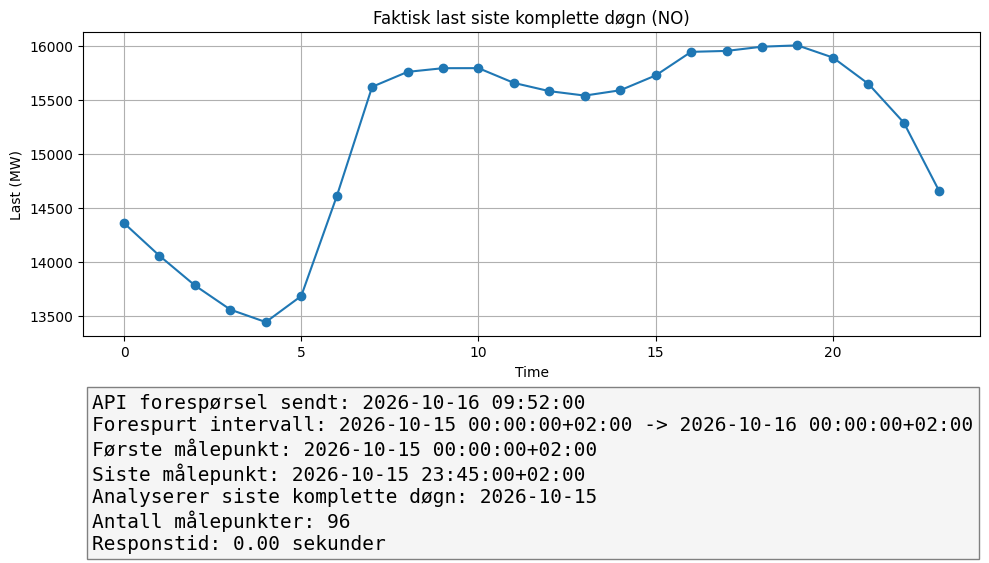

API forespørsel sendt: 2026-10-16 09:52:00
Forespurt intervall: 2026-10-15 00:00:00+02:00 -> 2026-10-16 00:00:00+02:00
Første målepunkt: 2026-10-15 00:00:00+02:00
Siste målepunkt: 2026-10-15 23:45:00+02:00
Analyserer siste komplette døgn: 2026-10-15
Antall målepunkter: 96
Hentet 96 målepunkter
Responstid: 0.00 sekunder


In [27]:
# TEST CELL
from dotenv import load_dotenv
import os
import pandas as pd
from entsoe import EntsoePandasClient
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import time
import matplotlib as mpl

mpl.rcParams["svg.fonttype"] = "none"


load_dotenv("../.env")

client = EntsoePandasClient(
    api_key=os.getenv("ENTSOE_API_KEY")
)

today = pd.Timestamp.now(tz="Europe/Oslo").normalize()
start = today - pd.Timedelta(days=1)
end = today

load = client.query_load(
    country_code="NO",
    start=start,
    end=end
)

load_hourly = load.resample("h").mean()

request_time = datetime.now()
tic = time.perf_counter()

toc = time.perf_counter()

fig, ax = plt.subplots(figsize=(10,4))

ax.plot(
    load_hourly.index.hour,
    load_hourly["Actual Load"],
    marker="o"
)

ax.set_title("Faktisk last siste komplette døgn (NO)")
ax.set_xlabel("Time")
ax.set_ylabel("Last (MW)")
ax.grid(True)

info = (
    f"API forespørsel sendt: {request_time:%Y-%m-%d %H:%M:%S}\n"
    f"Forespurt intervall: {start} -> {end}\n"
    f"Første målepunkt: {load.index.min()}\n"
    f"Siste målepunkt: {load.index.max()}\n"
    f"Analyserer siste komplette døgn: {start.strftime('%Y-%m-%d')}\n"
    f"Antall målepunkter: {len(load)}\n"
    f"Responstid: {toc - tic:.2f} sekunder"
)

fig.tight_layout()


ax.text(
    0.01, -0.7,
    info,
    transform=ax.transAxes,
    fontsize=14,
    family="monospace",
    bbox=dict(facecolor="whitesmoke", edgecolor="gray")
)

fig.savefig("figur.png")
fig.savefig(
    "lastprofilinfo.svg",
    format="svg",
    bbox_inches="tight",
    facecolor="white",
    transparent=False
)

plt.show()



print(f"API forespørsel sendt: {request_time:%Y-%m-%d %H:%M:%S}")
print(f"Forespurt intervall: {start} -> {end}")
print(f"Første målepunkt: {load.index.min()}")
print(f"Siste målepunkt: {load.index.max()}")
print(f"Analyserer siste komplette døgn: "f"{start.strftime('%Y-%m-%d')}")
print(f"Antall målepunkter: {len(load)}")
print(f"Hentet {len(load)} målepunkter")
print(f"Responstid: {toc - tic:.2f} sekunder")


<Figure size 1000x500 with 0 Axes>

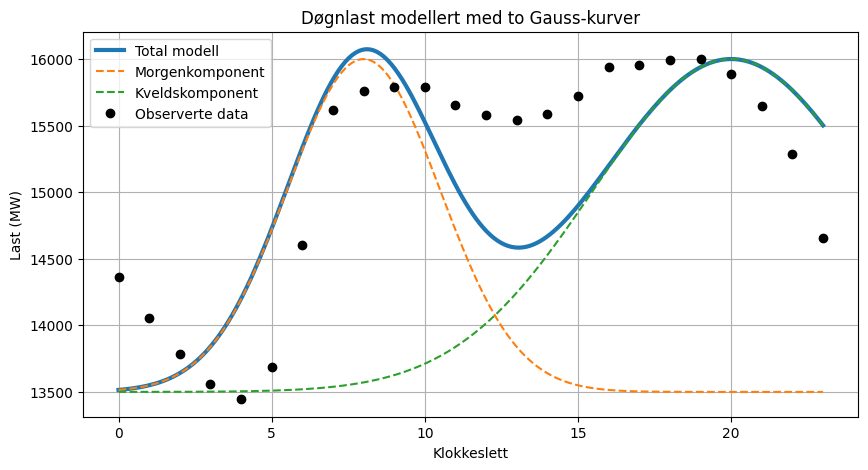

In [39]:
plt.figure(figsize=(10, 5))

t = np.linspace(0, 23, 200)

base_load = 13500

#night_decline = 800 * np.exp(-0.5*(t+2/10)**2)
morning_peak = 2500 * np.exp(-0.5*((t-8)/2.5)**2)
evening_peak = 2500 * np.exp(-0.5*((t-20)/4.5)**2)

model_load = (
    base_load
#    + night_decline
    + morning_peak
    + evening_peak
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(t, model_load, label="Total modell", linewidth=3)
ax.plot(t, base_load + morning_peak, "--", label="Morgenkomponent")
ax.plot(t, base_load + evening_peak, "--", label="Kveldskomponent")

ax.plot(
    load_hourly.index.hour,
    load_hourly.values,
    "ko",
    label="Observerte data"
)

ax.set_xlabel("Klokkeslett")
ax.set_ylabel("Last (MW)")
ax.set_title("Døgnlast modellert med to Gauss-kurver")
ax.grid(True)
ax.legend()

fig.savefig("gauss_model1.svg")
plt.show()